# Домашнее задание: введение в статистику
Васильева Анна 

In [16]:
import math
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm, t as t_dist, ttest_ind, mannwhitneyu

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
ALPHA = 0.05
SEED = 7   # стартовое число генератора для задач 4–7

## Задача 1.

**Гипотезы:**
- $H_0:\ \mu = 120$ — среднее время на карточке вакансии равно 120 секундам (наблюдаемое отклонение — шум выборки).
- $H_1:\ \mu \ne 120$ — среднее время на карточке отличается от 120 секунд.

Уровень значимости $\alpha = 0{,}05$.

Данные: $n=100$, $\bar x = 124$, $\sigma = 25$ (известна заранее, поэтому z-тест).

$$SE(\bar x)=\frac{\sigma}{\sqrt n},\qquad z=\frac{\bar x-\mu_0}{SE(\bar x)}$$

In [17]:
n, x_bar, mu0, sigma = 100, 124, 120, 25
se = sigma / math.sqrt(n)
z = (x_bar - mu0) / se
z_crit = norm.ppf(1 - ALPHA / 2)
p_value = 2 * norm.sf(abs(z))

ci_low = x_bar - z_crit * se
ci_high = x_bar + z_crit * se

print(f"SE = {se:.2f} c")
print(f"z = {z:.2f} (критическое значение ±{z_crit:.2f})")
print(f"p-value = {p_value:.4f}")
print(f"95% ДИ для среднего = [{ci_low:.1f}; {ci_high:.1f}] с")

SE = 2.50 c
z = 1.60 (критическое значение ±1.96)
p-value = 0.1096
95% ДИ для среднего = [119.1; 128.9] с


**Вывод.** Гипотеза продукта "среднее время на карточке вакансии равно 120 секундам" по этим данным не опровергнута. В выборке из 100 пользователей среднее 124 с, это на 4 с больше. Такое отклонение укладывается в обычный случайный разброс: $z = 1{,}6$ при пороге $1{,}96$, $p = 0{,}1096 > 0{,}05$. 95% доверительный интервал для среднего времени — $[119{,}1;\ 128{,}9]$ секунд, значение 120 внутри него.
Чтобы надёжно заметить отклонение в 4 секунды, нужно примерно 307 пользователей вместо 100.

$$n=\left(\frac{(z_{1-\alpha/2}+z_{1-\beta})\,\sigma}{\bar x-\mu_0}\right)^2=\left(\frac{(1{,}96+0{,}84)\cdot 25}{124-120}\right)^2\approx 307$$

## Задача 2.

Дисперсии генеральных совокупностей неизвестны, но равны, значит это классический t-тест Стьюдента с общей оценкой $s_p$ и $n_1+n_2-2$ степенями свободы.

- $H_0:\ \mu_2 - \mu_1 = 0$ — средние двух групп равны.
- $H_1:\ \mu_2 - \mu_1 \ne 0$ — средние двух групп различаются.

$$s_p=\sqrt{\frac{(n_1-1)s_1^2+(n_2-1)s_2^2}{n_1+n_2-2}},\quad SE(\hat\Delta)=s_p\sqrt{\tfrac1{n_1}+\tfrac1{n_2}},\quad CI=\hat\Delta\pm t_{1-\alpha/2,\nu}\cdot SE(\hat\Delta)$$

In [18]:
n1, m1, s1 = 40, 50, 10
n2, m2, s2 = 40, 55, 10

delta = m2 - m1
df = n1 + n2 - 2
sp = math.sqrt(((n1 - 1) * s1**2 + (n2 - 1) * s2**2) / df)
se = sp * math.sqrt(1 / n1 + 1 / n2)
t_stat = delta / se
t_crit = t_dist.ppf(1 - ALPHA / 2, df)
ci_low, ci_high = delta - t_crit * se, delta + t_crit * se
p_value = 2 * t_dist.sf(abs(t_stat), df)

print(f"разница средних = {delta}")
print(f"s_p = {sp:.2f}, SE = {se:.3f}, df = {df}, t_крит = {t_crit:.3f}")
print(f"95% CI = [{ci_low:.3f}; {ci_high:.3f}]")
print(f"t = {t_stat:.3f}, p-value = {p_value:.4f}")

разница средних = 5
s_p = 10.00, SE = 2.236, df = 78, t_крит = 1.991
95% CI = [0.548; 9.452]
t = 2.236, p-value = 0.0282


**Вывод.** Вторая группа в среднем выше первой на 5 единиц. Это отличие статистически значимо: $t = 2{,}24$, $p = 0{,}028 < 0{,}05$, поэтому $H_0$ средние равны отвергаем.

95% доверительный интервал для разницы — $[0{,}548;\ 9{,}452]$. Ноль в него не попадает, значит разница в пользу второй группы не случайна. Самый маленький эффект, который ещё согласуется с данными, — около $+0{,}55$.

Вторая группа лучше первой, но насколько не понятно. Реальная разница может быть как почти незаметной (около 0,5), так и существенной (около 9,5). Чтобы сузить интервал и точнее оценить эффект, нужна выборка побольше.

## Задача 3. 

Показы независимы, группы независимы, значит z-критерий применим.
- $H_0:\ p_1 = p_2$ — конверсии двух групп равны.
- $H_1:\ p_1 \ne p_2$ — конверсии двух групп различаются.

$$z=\frac{\hat p_2-\hat p_1}{\sqrt{\hat p(1-\hat p)\left(\frac1{n_2}+\frac1{n_1}\right)}},\qquad \hat p=\frac{x_1+x_2}{n_1+n_2}$$

In [ ]:
x1, n1 = 90, 1000
x2, n2 = 120, 1000
p1, p2 = x1 / n1, x2 / n2
p_pool = (x1 + x2) / (n1 + n2)

diff_pp = (p2 - p1) * 100
z = (p2 - p1) / math.sqrt(p_pool * (1 - p_pool) * (1 / n2 + 1 / n1))
p_value = 2 * norm.sf(abs(z))

se_diff = math.sqrt(p1 * (1 - p1) / n1 + p2 * (1 - p2) / n2)
z_crit = norm.ppf(1 - ALPHA / 2)
ci_low = (p2 - p1) - z_crit * se_diff
ci_high = (p2 - p1) + z_crit * se_diff

print(f"95% ДИ для разницы = [{ci_low*100:.1f}; {ci_high*100:.1f}]")
print(f"p1 = {p1:.3f}, p2 = {p2:.3f}, p (объединённая) = {p_pool:.3f}")
print(f"разница = {diff_pp:.1f}")
print(f"z = {z:.3f}, p-value = {p_value:.4f}")

95% ДИ для разницы = [0.3; 5.7] п.п.
p1 = 0.090, p2 = 0.120, p (объединённая) = 0.105
разница = 3.0
z = 2.188, p-value = 0.0287



**Вывод.** Конверсия в отклик у второй группы выше: 12% и 9% соответственно, разница +3. $z = 2{,}19$ выходит за порог $\pm 1{,}96$, $p-value = 0{,}029 < 0{,}05$. Отвергаем $H_0$ ($p_1 = p_2$): различие конверсий нельзя объяснить случайным шумом выборки.

Критерий применим: исходы бинарные (откликнулся / не откликнулся), группы независимы, выборки большие (по 1000 показов).

95% ДИ для разницы конверсий — $[0{,}3;\ 5{,}7]$. Ноль в интервал не попадает, значит точно отвергаем $H_0$. Но интервал широкий: настоящий прирост может быть как совсем небольшим (около 0,3), так и значительным (около 5,7).

Изменение, скорее всего, работает и конверсия действительно выросла. Но величина эффекта оценена неточно, поэтому прогнозировать нужно, ориентируясь на нижнюю границу интервала. 

## Задача 4.

Генератор: `rng = np.random.default_rng(7)`. 2000 раз берём две группы по 200 наблюдений из одного и того же $N(0,1)$, значит $H_0$ верна всегда. Считаем t Уэлча и p-value.

доля p-value <= 0.05: 0.057  (ожидаем ~ 0.05)


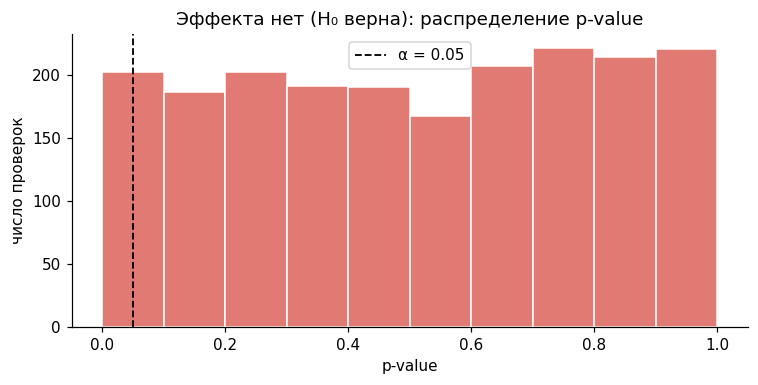

In [ ]:
rng = np.random.default_rng(SEED)
N_REP, N_OBS = 2000, 200

p_values = np.empty(N_REP)
for i in range(N_REP):
    a = rng.normal(0, 1, N_OBS)
    b = rng.normal(0, 1, N_OBS)
    p_values[i] = ttest_ind(b, a, equal_var=False).pvalue

print(f"доля p-value <= 0.05: {(p_values <= ALPHA).mean():.3f}  (ожидаем ~ {ALPHA})")

fig, ax = plt.subplots(figsize=(7, 3.6))
ax.hist(p_values, bins=10, range=(0, 1), color="#E07A72", edgecolor="white")
ax.axvline(ALPHA, color="black", ls="--", lw=1.2, label="α = 0.05")
ax.set_xlabel("p-value"); ax.set_ylabel("число проверок")
ax.set_title("Эффекта нет (H0 верна): распределение p-value")
ax.legend(); plt.tight_layout(); plt.show()

**Вывод.** Распределение p-value плоское (равномерное на отрезке $[0,\,1]$): столбцы гистограммы примерно одной высоты, горки у нуля нет.

В каждом из 2000 повторов обе группы взяты из одного и того же $N(0,\,1)$, то есть $H_0$ верна всегда. Если $H_0$ верна, а критерий непрерывный и посчитан правильно, p-value принимает любое значение от 0 до 1 с одинаковой вероятностью. Поэтому вероятность получить $p \le 0{,}05$ равна ровно 5%, и столбцы гистограммы примерно одинаковы.

## Задача 5.

1000 повторов. Первая группа: $N(0,1)$, $n=60$. Вторая: $N(1,1)$, $n=60$, после чего два её наблюдения заменены на $-50$. Настоящий сдвиг есть (на 1), но выбросы его маскируют для среднего.

In [27]:
rng = np.random.default_rng(SEED)
N_REP = 1000
rows = []
for _ in range(N_REP):
    a = rng.normal(0, 1, 60)          # первая группа
    b = rng.normal(1, 1, 60)          # вторая группа
    b[:2] = -50                       # два наблюдения заменяем на -50
    tt = ttest_ind(b, a, equal_var=False)                       # t Уэлча (вторая - первая)
    uu = mannwhitneyu(a, b, alternative="two-sided")            # U для первой группы
    rows.append((b.mean() - a.mean(), tt.statistic, tt.pvalue, uu.statistic, uu.pvalue))

diff_means, t_stats, p_t, u_stats, p_u = np.array(rows).T

print(f"Средняя разница средних (вторая - первая): {diff_means.mean():+.3f}  (без выбросов было бы около +1)")
print(f"t Уэлча:  медиана {np.median(t_stats):+.2f}, 2.5–97.5 перцентили [{np.percentile(t_stats,2.5):+.2f}; {np.percentile(t_stats,97.5):+.2f}]")
print(f"U (первая группа): медиана {np.median(u_stats):.0f}, 2.5–97.5 перцентили [{np.percentile(u_stats,2.5):.0f}; {np.percentile(u_stats,97.5):.0f}]; при H0 ожидалось бы 60*60/2 = 1800")
print(f"доля отвержений H0 при 5%:  t Уэлча = {(p_t<=ALPHA).mean():.3%},  U Манна–Уитни = {(p_u<=ALPHA).mean():.3%}")
print(f"выводы совпали в {((p_t<=ALPHA)==(p_u<=ALPHA)).mean():.1%} повторов")

Средняя разница средних (вторая - первая): -0.686  (без выбросов было бы около +1)
t Уэлча:  медиана -0.57, 2.5–97.5 перцентили [-0.88; -0.29]
U (первая группа): медиана 940, 2.5–97.5 перцентили [677; 1236]; при H0 ожидалось бы 60*60/2 = 1800
доля отвержений H0 при 5%:  t Уэлча = 0.000%,  U Манна–Уитни = 100.000%
выводы совпали в 0.0% повторов


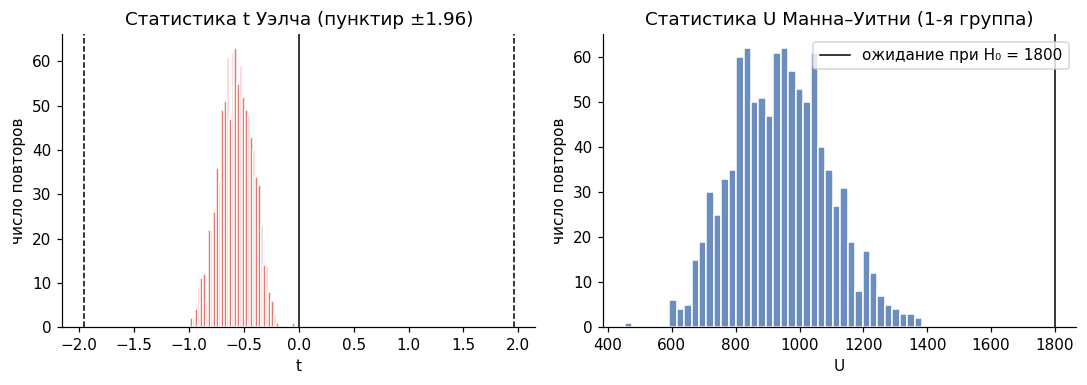

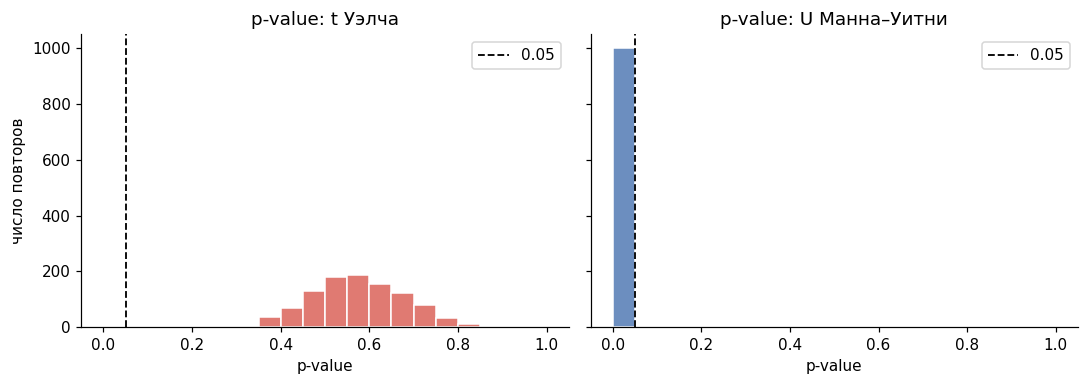

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
axes[0].hist(t_stats, bins=40, color="#E07A72", edgecolor="white")
axes[0].axvline(0, color="black", lw=1)
axes[0].axvline(-1.96, color="black", ls="--", lw=1); axes[0].axvline(1.96, color="black", ls="--", lw=1)
axes[0].set_title("Статистика t Уэлча (пунктир ±1.96)"); axes[0].set_xlabel("t")

axes[1].hist(u_stats, bins=40, color="#6C8EBF", edgecolor="white")
axes[1].axvline(1800, color="black", lw=1, label="ожидание при H0 = 1800")
axes[1].set_title("Статистика U Манна–Уитни (1-я группа)"); axes[1].set_xlabel("U"); axes[1].legend()
for ax in axes: ax.set_ylabel("число повторов")
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), sharey=True)
for ax, p, name, col in [(axes[0], p_t, "t Уэлча", "#E07A72"), (axes[1], p_u, "U Манна–Уитни", "#6C8EBF")]:
    ax.hist(p, bins=20, range=(0, 1), color=col, edgecolor="white")
    ax.axvline(ALPHA, color="black", ls="--", lw=1.2, label="0.05")
    ax.set_title(f"p-value: {name}"); ax.set_xlabel("p-value"); ax.legend()
axes[0].set_ylabel("число повторов")
plt.tight_layout(); plt.show()

**Где сосредоточены распределения.**
- $t$ Уэлча лежит около нуля, примерно от $-0{,}9$ до $-0{,}3$, то есть внутри порогов $\pm1{,}96$. Его p-value в основном большие, далеко от 0,05.
- $U$ лежит около 940 при ожидаемых 1800 под $H_0$: ранги первой группы систематически ниже. p-value практически нулевые, всё прижато к левому краю.

Решения при двустороннем пороге 5%. t Уэлча не отвергает $H_0$ ни разу (0% повторов), U Манна–Уитни отвергает всегда (100%). Выводы разошлись в каждом повторе.

1. Два выброса $-50$ тянут среднее второй группы вниз: примерно $1 + 2\cdot(-51)/60 \approx -0{,}7$. Разница средних оказывается около $-0{,}7$ вместо $+1$.
2. Выбросы сильно увеличивается выборочное СКО второй группы, а значит и стандартную ошибку. Статистика $t = \hat\Delta / SE$ остаётся малой. Среднее неустойчиво к выбросам при небольшом $n$.
3. U работает по рангам: каждый выброс - одно из самых низких значений (два самых низких ранга), величина $-50$ ничего не значит. Остальные 58 наблюдений второй группы сдвинуты на $+1$.
4. Критерии проверяют разные $H_0$: t Уэлча — равенство средних, Манна–Уитни — равенство распределений (вероятность превосходства). Расхождение - это не противоречие, а разные вопросы к одним данным: среднее второй группы из-за выбросов ниже, а наблюдение второй группы выше. Какой критерий нужен, определяется вопросом бизнеса.

## Задача 6. 

Один раз берём первую группу из $N(10,2)$, $n_1=80$, вторую из $N(10{,}8;\,2{,}6)$, $n_2=75$. Эффект — вторая минус первая, $H_0:\ \Delta=0$.

In [28]:
rng = np.random.default_rng(SEED)
group1 = rng.normal(10, 2, 80)
group2 = rng.normal(10.8, 2.6, 75)

print(f"группа 1: n={group1.size}, mean={group1.mean():.3f}, s={group1.std(ddof=1):.3f}")
print(f"группа 2: n={group2.size}, mean={group2.mean():.3f}, s={group2.std(ddof=1):.3f}")

res = ttest_ind(group2, group1, equal_var=False, alternative="two-sided")
ci = res.confidence_interval(confidence_level=0.95)
diff = group2.mean() - group1.mean()

print(f"\nразница средних = {diff:.3f}")
print(f"t Уэлча = {res.statistic:.3f}, df = {res.df:.1f}, p-value = {res.pvalue:.4f}")
print(f"95% ДИ Уэлча = [{ci.low:.3f}; {ci.high:.3f}]")
print("0 внутри интервала:", ci.low <= 0 <= ci.high)

группа 1: n=80, mean=9.647, s=1.781
группа 2: n=75, mean=10.404, s=2.255

разница средних = 0.757
t Уэлча = 2.308, df = 140.8, p-value = 0.0225
95% ДИ Уэлча = [0.109; 1.404]
0 внутри интервала: False


**Вывод.** Среднее второй группы выше первой: 10,4 против 9,65, разница средних $+0{,}757$. Критерий Уэлча даёт $t = 2{,}31$, $p = 0{,}022 < 0{,}05$, поэтому отвергаем $H_0$.

95% доверительный интервал для разницы — $[0{,}109;\ 1{,}404]$. Ноль в интервал не попадает, снова отвергаем $H_0$. Самый маленький эффект, который ещё согласуется с данными, — около $+0{,}11$ (нижняя граница интервала).


## Задача 7. 

Те же две группы (group1, group2 из задачи 6). 2000 раз берём из каждой группы выборку того же размера и считаем разницу средних. 95% интервал — границы, отсекающие по 2,5% с каждого края.

бутстрап 95% ИД = [0.111; 1.403]
Уэлч     95% ДИ = [0.109; 1.404]
доля бутстрап-разниц <= 0: 0.0090


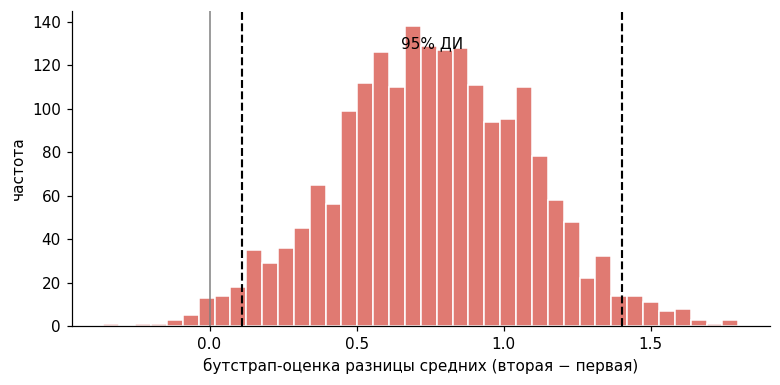

In [ ]:
B = 2000
boot_diffs = np.empty(B)
for i in range(B):
    s1 = rng.choice(group1, size=group1.size, replace=True)
    s2 = rng.choice(group2, size=group2.size, replace=True)
    boot_diffs[i] = s2.mean() - s1.mean()

boot_low, boot_high = np.percentile(boot_diffs, [2.5, 97.5])
share_le_zero = (boot_diffs <= 0).mean()

print(f"бутстрап 95% ИД = [{boot_low:.3f}; {boot_high:.3f}]")
print(f"Уэлч 95% ДИ = [{ci.low:.3f}; {ci.high:.3f}]")
print(f"доля бутстрап-разниц <= 0: {share_le_zero:.4f}")

fig, ax = plt.subplots(figsize=(7.2, 3.6))
ax.hist(boot_diffs, bins=40, color="#E07A72", edgecolor="white")
ax.axvline(boot_low, color="black", ls="--", lw=1.4)
ax.axvline(boot_high, color="black", ls="--", lw=1.4)
ax.axvline(0, color="grey", lw=1)
ymax = ax.get_ylim()[1]
ax.text((boot_low + boot_high) / 2, ymax * 0.92, "95% ДИ", ha="center", va="top")
ax.set_xlabel("бутстрап-оценка разницы средних"); ax.set_ylabel("частота")
plt.tight_layout(); plt.show()

**Сравнение интервалов.** Бутстрап: $[0{,}111;\ 1{,}403]$, интервал Уэлча: $[0{,}109;\ 1{,}404]$. Границы почти совпадают, ноль не попадает ни в один. Это ожидаемо: группы довольно большие ($n\approx 80$), и t-тест для разницы средних работает хорошо. Для обычного среднего независимых пользователей t-тест проще и мощнее, бутстрап здесь ничего не добавляет.

**Доля повторов с разницей $\le 0$ — около 0,9%.** Можно ли назвать её p-value? Нет.
- p-value — это вероятность увидеть наблюдаемую или более экстремальную разницу при условии, что $H_0$ верна. Бутстрап распределение построено из реальных данных и центрировано около наблюдаемой разницы $+0{,}757$, а не около нуля. Доля «$\le 0$» — это оценка того, насколько ноль далёк от оценки, а не вероятность при $H_0$.
- Эта доля односторонняя. Для двустороннего порога её нужно удвоить, получится около 0,018, что близко к $p=0{,}022$ у критерия Уэлча. Это совпадение следствие двойственности интервала и проверки гипотезы, а не определения p-value.
- Чтобы получить настоящий бутстрап-p-value, нужно обе группы объединить в одну общую кучу данных. Из этой кучи много раз случайно набирают две новые выборки нужного размера и каждый раз считают разницу средних. Получается набор разниц, которые бывают просто из-за случайности. Затем смотрим, в какой доле случаев эта случайная разница оказалась не меньше наблюдаемой по модулю. Эта доля и есть p-value.

In [ ]:
# Для сравнения: настоящий бутстрап-p-value при H0 
pooled = np.concatenate([group1, group2])
h0_diffs = np.array([
    rng.choice(pooled, size=group2.size, replace=True).mean()
    - rng.choice(pooled, size=group1.size, replace=True).mean()
    for _ in range(20_000)
])
p_boot_h0 = (np.abs(h0_diffs) >= abs(diff)).mean()
print(f"двусторонний бутстрап-p-value при H0: {p_boot_h0:.4f} (Уэлч: {res.pvalue:.4f})")
print(f"удвоенная доля из основного бутстрапа: {2 * share_le_zero:.4f}")

двусторонний бутстрап-p-value при H0: 0.0217   (Уэлч: 0.0225)
удвоенная доля из основного бутстрапа: 0.0180


Бутстрап-p-value при $H_0$ почти совпал с $p$ Уэлча. Все три подхода (интервал Уэлча, бутстрап-интервал и проверка при $H_0$) дают согласованный вывод: эффект положительный, $H_0$ отвергаем, но его размер может быть небольшим (от $0{,}1$ до $1{,}4$).